# Average vs total log likelihood for DC-PMI

Reproduce the **All models: first-error AUROC and significance by benchmark** plot from `context-relevance-plots.ipynb` with the same cached likelihoods. Total LL uses the sum of token log probabilities in each context; average LL divides each context's sum by its own number of step tokens before subtraction. Perplexity is unchanged.

AUROC pools every step within each benchmark, including post-error steps. Only the annotated first-error step is positive. Lower DC-PMI and higher perplexity indicate an error. One-sided Mann–Whitney U tests ask whether error-evidence scores are higher at first-error steps. Bars with unadjusted $p \ge 0.05$ are faded.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

from experiment_setup import dc_pmi
from experiment_setup.benchmarks import load_examples
from experiment_setup.plots import METRIC_LABELS

CACHE = Path('cache')
MODELS = {'4B': 'Qwen/Qwen3.5-4B', '9B': 'Qwen/Qwen3.5-9B', '27B': 'Qwen/Qwen3.5-27B'}

# Match the original plot's exclusion of the invalid Dyck-language example.
examples = [
    example for task in load_examples().values() for example in task
    if not (example.benchmark == 'BIG-Bench-Mistake'
            and example.task == 'dyck_languages' and example.uid == '52')
]
assert len(examples) == 8584
benchmarks = list(dict.fromkeys(example.benchmark for example in examples))


## All models: first-error AUROC and significance by benchmark

First three plots: total LL. Next three plots: average LL. Each set contains one plot per model.

2026-11-06 15:54:25 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_4b_arm.sqlite
2026-11-06 15:54:31 INFO experiment_setup: Loaded records


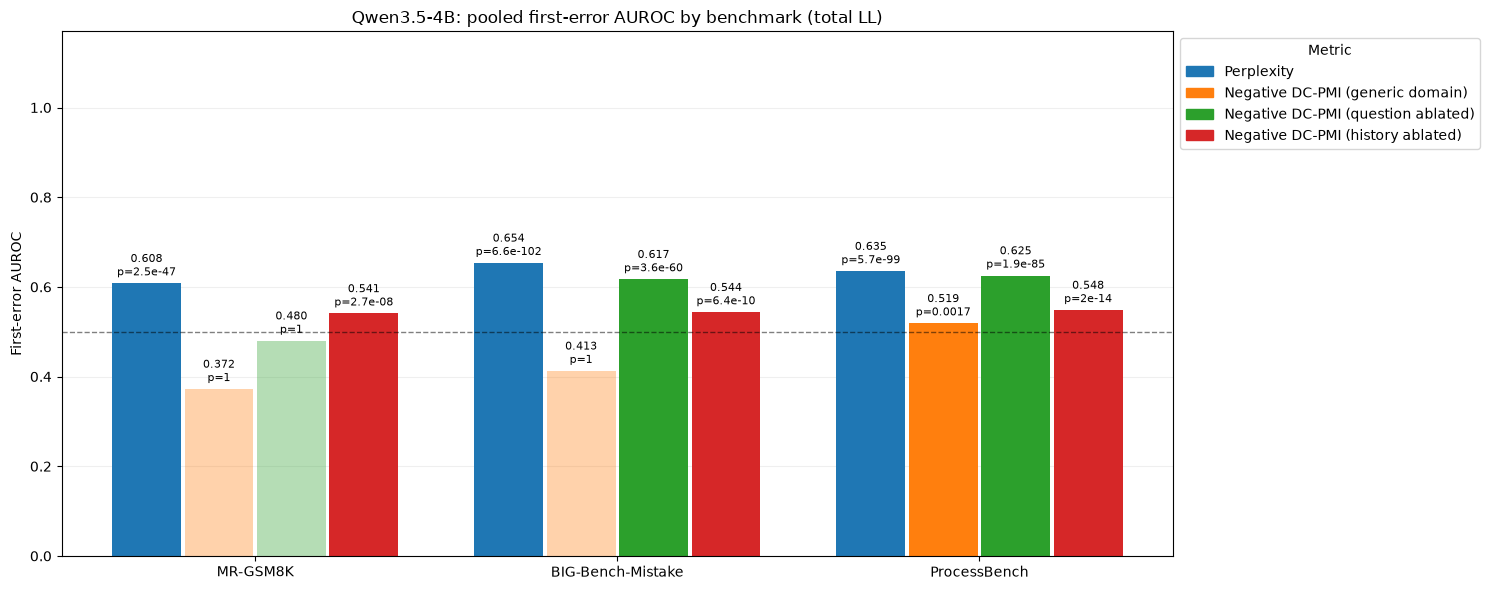

2026-11-06 15:54:33 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_9b_arm.sqlite
2026-11-06 15:54:40 INFO experiment_setup: Loaded records


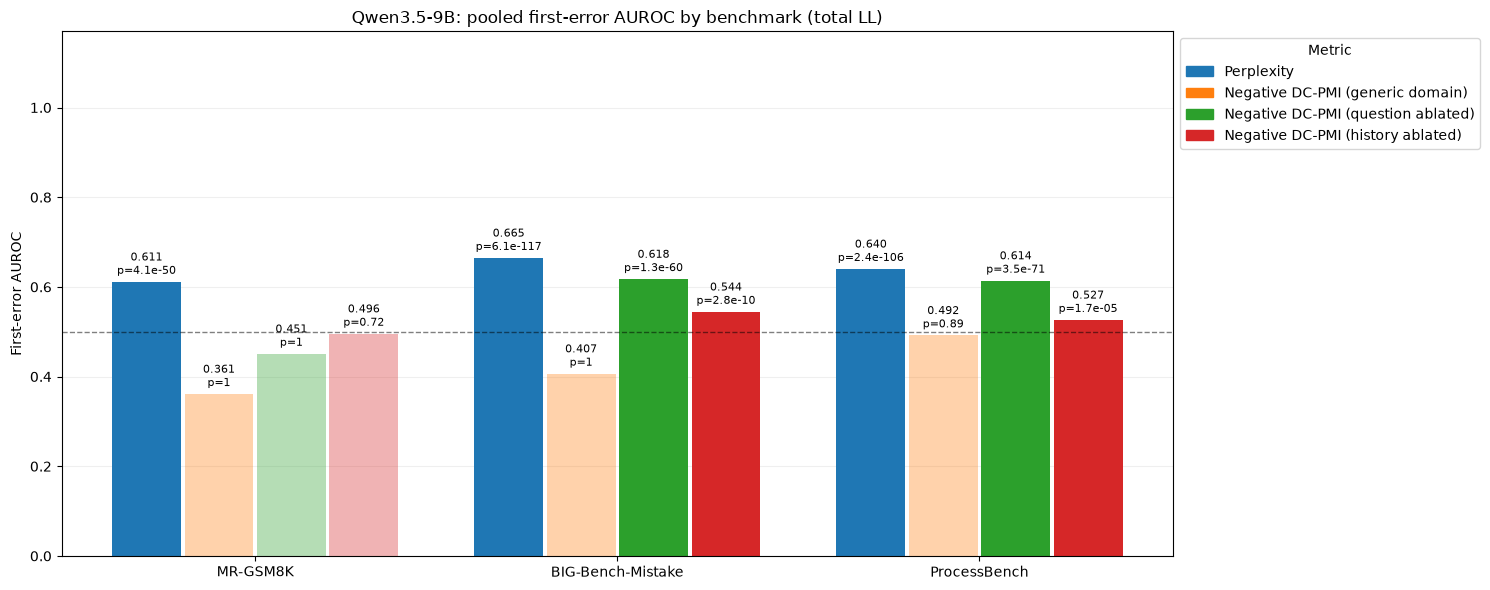

2026-11-06 15:54:42 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_27b_arm.sqlite
2026-11-06 15:54:49 INFO experiment_setup: Loaded records


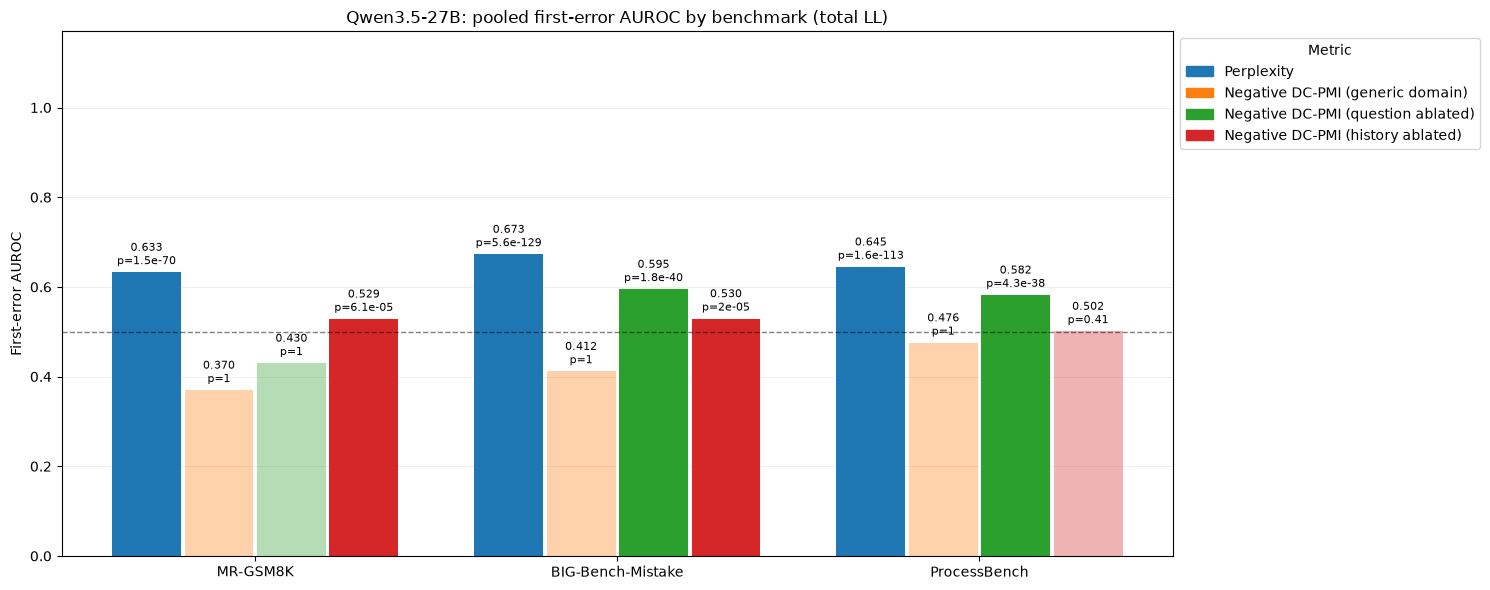

2026-11-06 15:54:51 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_4b_arm.sqlite
2026-11-06 15:54:56 INFO experiment_setup: Loaded records


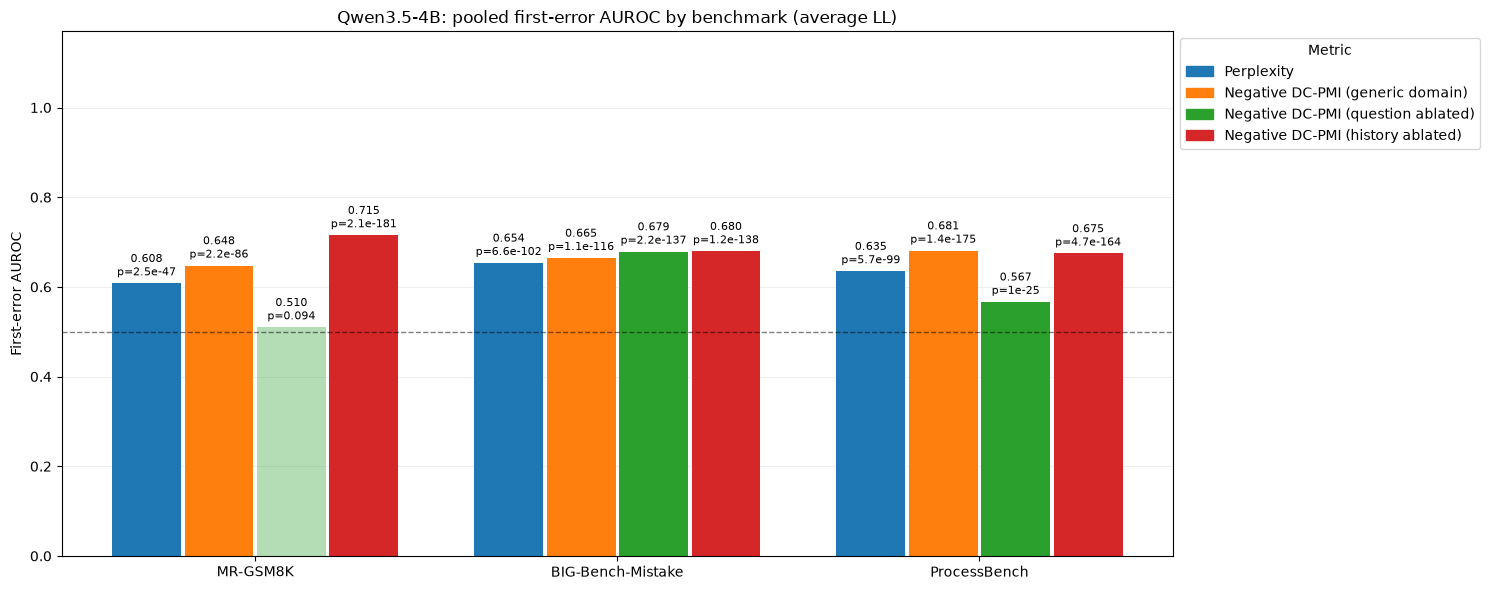

2026-11-06 15:54:59 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_9b_arm.sqlite
2026-11-06 15:55:04 INFO experiment_setup: Loaded records


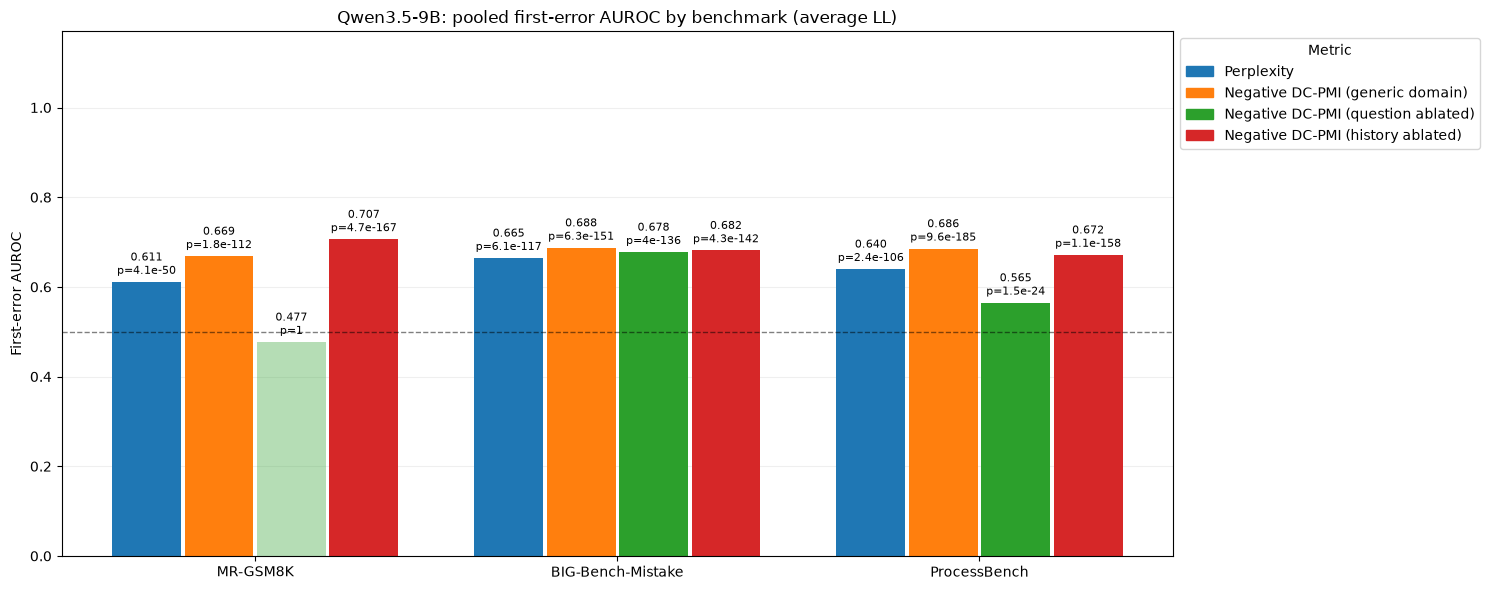

2026-11-06 15:55:06 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_27b_arm.sqlite
2026-11-06 15:55:21 INFO experiment_setup: Loaded records


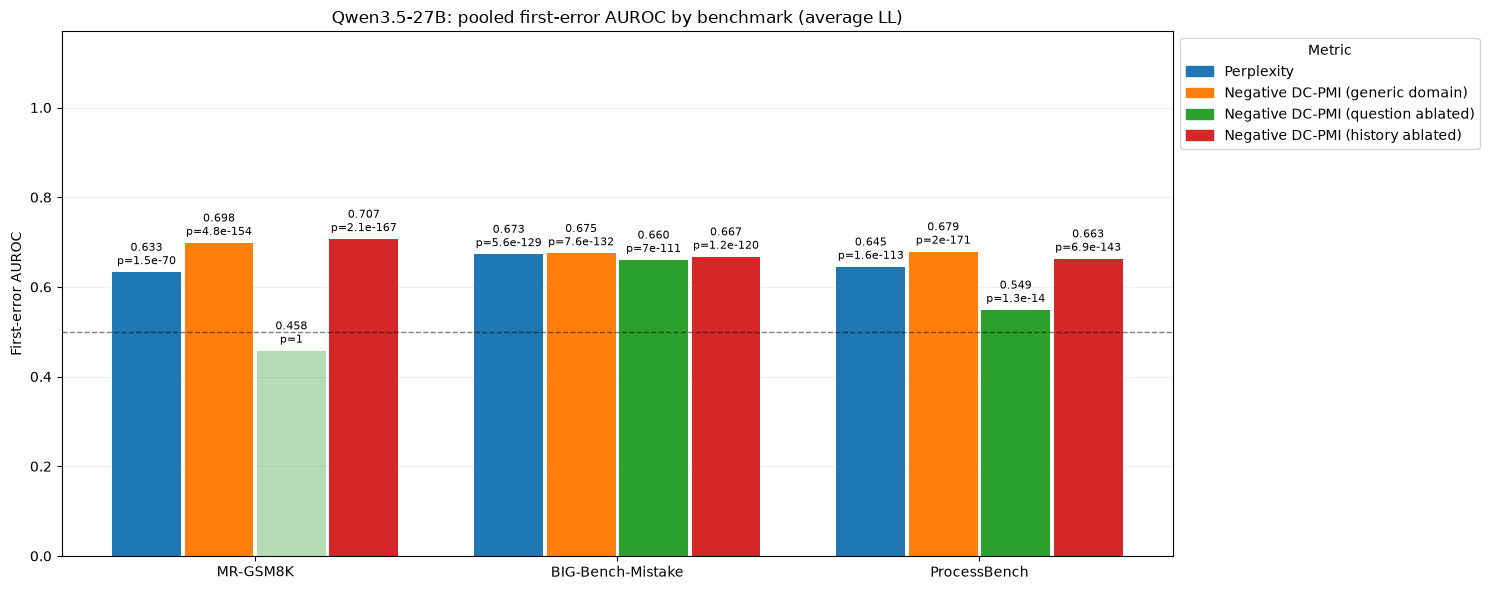

In [2]:
for average_ll, method in [(False, 'total LL'), (True, 'average LL')]:
    for model, model_id in MODELS.items():
        scores = dc_pmi.load_run(
            examples, model_id=model_id, average_ll=average_ll,
            cache_path=CACHE / f'dc_pmi_qwen35_{model.lower()}_arm.sqlite',
        )
        assert scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples)
        fig, ax = plt.subplots(figsize=(15, 6))
        for benchmark_index, benchmark in enumerate(benchmarks):
            group = scores.loc[scores.benchmark == benchmark]
            assert group.first_error.nunique() == 2
            for metric_index, metric in enumerate(dc_pmi.METRICS):
                evidence = dc_pmi.error_evidence_score(group, metric)
                positives = evidence.loc[group.first_error]
                negatives = evidence.loc[~group.first_error]
                auc = roc_auc_score(group.first_error, evidence)
                p_value = mannwhitneyu(positives, negatives, alternative='greater').pvalue
                x = benchmark_index + (metric_index - (len(dc_pmi.METRICS) - 1) / 2) * 0.2
                bar = ax.bar(x, auc, width=0.19, color=f'C{metric_index}')
                if p_value >= 0.05:
                    bar[0].set_alpha(0.35)
                ax.bar_label(bar, labels=[f'{auc:.3f}\np={p_value:.2g}'], padding=3, fontsize=8)
        ax.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
        ax.set(xticks=range(len(benchmarks)), xticklabels=benchmarks,
               ylabel='First-error AUROC', ylim=(0, 1.17),
               title=f'Qwen3.5-{model}: pooled first-error AUROC by benchmark ({method})')
        ax.legend(handles=[Patch(color=f'C{i}', label=METRIC_LABELS[metric])
                           for i, metric in enumerate(dc_pmi.METRICS)],
                  title='Metric', loc='upper left', bbox_to_anchor=(1, 1))
        ax.grid(axis='y', alpha=0.2)
        ax.set_axisbelow(True)
        fig.tight_layout()
        display(fig)
        plt.close(fig)
